# DSCI 552 — Homework 8
**Name:** Chengfeng Tang  
**GitHub username:** tcf2021  
**USC ID:** 5488902262

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
ROOT=Path("..") if Path("../data/wdbc.data").exists() else Path(".")
sys.path.insert(0,str((ROOT/"src").resolve()))
from experiments import run_breast, run_bank, SEED
DATA,OUT=ROOT/"data",ROOT/"results"
OUT.mkdir(exist_ok=True)
# Set True to repeat every fit; False displays the saved complete experiments.
RECOMPUTE=False
def table(df,name):
    df.to_csv(OUT/(name+".csv"),index=False)
    display(df.round(6))
def answer(s):
    display(Markdown(s))
def figure(name):
    plt.savefig(OUT/(name+".png"),dpi=150,bbox_inches="tight")
    plt.show()

## 1(a). Breast Cancer Wisconsin (Diagnostic)
I used the supplied WDBC file. The 30 numerical attributes are predictors; the ID is excluded. I encoded benign as 0 and malignant as 1, so precision, recall, F1, and ROC treat malignancy as the positive class.

In [2]:
wdbc=pd.read_csv(DATA/"wdbc.data",header=None)
print("Observations:",len(wdbc),"Predictors:",wdbc.shape[1]-2)
display(wdbc[1].value_counts().rename_axis("Diagnosis").to_frame("Count"))
assert wdbc.shape==(569,32) and not wdbc.isna().any().any()

Observations: 569 Predictors: 30


,Count
Diagnosis,
B,357
M,212


## 1(b). Thirty Monte Carlo repetitions
In each repetition I independently sampled 20% of each class for testing, rounding upward to whole observations: 72 benign and 43 malignant test cases. The remaining 285 benign and 169 malignant cases form the training set. All four methods share the same split within each repetition.

I scaled each feature to the training minimum/maximum range. Test values are transformed with these training statistics and are not clipped. SVM cross-validation fits its scaler within each fitting fold. The C grid is {0.01, 0.1, 1, 10, 100}; five-fold stratified validation accuracy selects C, with smaller C winning a tie. The SVM uses an L1 penalty, squared-hinge loss, and a linear decision boundary. If LIBLINEAR reaches its iteration limit, I increase that limit. If it still stalls, I minimize the same L1 squared-hinge primal objective with a nonnegative split of each coefficient and check the projected gradient. The objective includes the penalized intercept used by LinearSVC.

The helper functions carry out the complete experiments and save all 30 runs, CV scores, splits, and pseudo-label acquisition traces. The tables below display those saved results; changing RECOMPUTE to True reruns every fit.

In [3]:
if RECOMPUTE or not (OUT/"breast_metrics.csv").exists():
    breast=run_breast(DATA,OUT)
else:
    breast=pd.read_csv(OUT/"breast_metrics.csv")
assert breast.groupby(["method","split"]).size().eq(30).all()
metrics=["accuracy","precision","recall","F1","AUC"]
means=breast.groupby(["method","split"],sort=False)[metrics].mean().reset_index()
stds=breast.groupby(["method","split"],sort=False)[metrics].std(ddof=1).reset_index()
table(means,"breast_mean_scores")
table(stds,"breast_sd_scores")
predictions=pd.read_csv(OUT/"breast_run1_predictions.csv")
def run_one(method):
    rows=[]
    fig,axes=plt.subplots(1,2,figsize=(9,3.7),layout="constrained")
    for ax,split in zip(axes,["Train","Test"]):
        d=predictions[(predictions.method==method)&(predictions.split==split)]
        cm=confusion_matrix(d.truth,d.prediction,labels=[0,1])
        print(method,split)
        display(pd.DataFrame(cm,index=["Actual benign","Actual malignant"],columns=["Pred benign","Pred malignant"]))
        fpr,tpr,_=roc_curve(d.truth,d.score)
        ax.plot(fpr,tpr,label=f"AUC = {roc_auc_score(d.truth,d.score):.4f}")
        ax.plot([0,1],[0,1],":",color="gray")
        ax.set(xlabel="False positive rate",ylabel="True positive rate",title=method+" — "+split)
        ax.legend(loc="lower right")
    figure(method.lower().replace("-","_")+"_roc")

,method,split,accuracy,precision,recall,F1,AUC
0,Supervised,Train,0.986490,0.990768,0.972781,0.981661,0.997704
1,Supervised,Test,0.961449,0.957377,0.940310,0.948121,0.991225
2,Self-training,Train,0.974156,0.982861,0.947337,0.964577,0.994564
3,Self-training,Test,0.960580,0.967204,0.927132,0.946142,0.989104
4,K-means,Train,0.927166,0.953188,0.846154,0.896317,0.980736
5,K-means,Test,0.922319,0.942333,0.845736,0.890053,0.977379
6,Spectral,Train,0.857856,0.984647,0.628008,0.766217,0.811080
7,Spectral,Test,0.841449,0.967223,0.596124,0.713706,0.792043


,method,split,accuracy,precision,recall,F1,AUC
0,Supervised,Train,0.005630,0.006020,0.011895,0.007684,0.001362
1,Supervised,Test,0.015435,0.034998,0.029087,0.020393,0.007949
2,Self-training,Train,0.007384,0.012614,0.020636,0.010349,0.002285
3,Self-training,Test,0.017796,0.033149,0.034942,0.024430,0.009470
4,K-means,Train,0.007716,0.015421,0.017785,0.011386,0.002737
5,K-means,Test,0.021776,0.036978,0.054448,0.032845,0.009859
6,Spectral,Train,0.013916,0.008485,0.037928,0.028458,0.018755
7,Spectral,Test,0.075658,0.039555,0.203427,0.197412,0.101205


### 1(b)(i). Supervised learning
I fitted the L1 SVM to all 454 labeled training observations after selecting C by five-fold CV. The table averages each metric over the 30 runs. The confusion matrices and ROC curves use run 1, selected in advance.

Supervised Train
Supervised Test


,method,split,accuracy,precision,recall,F1,AUC
0,Supervised,Train,0.986490,0.990768,0.972781,0.981661,0.997704
1,Supervised,Test,0.961449,0.957377,0.940310,0.948121,0.991225


,Pred benign,Pred malignant
Actual benign,284,1
Actual malignant,3,166


,Pred benign,Pred malignant
Actual benign,69,3
Actual malignant,3,40


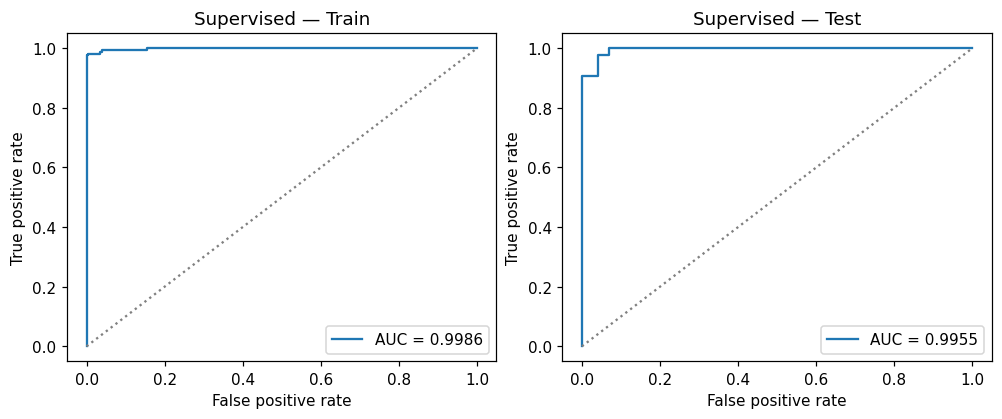

In [4]:
display(means.loc[means.method=="Supervised"].round(6))
run_one("Supervised")

### 1(b)(ii)(A). Initial labeled data
Within each training split I randomly selected half of each class, rounding downward: 142 benign and 84 malignant observations. These 226 labels were available initially; the other 228 labels were hidden. Five-fold CV used only the initial labeled subset to select C. The fixed normalization for self-training uses all available training features, including unlabeled features, and no test features.

### 1(b)(ii)(B). Self-training
At each step I selected the unlabeled observation with the largest absolute SVM decision value. For a fixed nonzero weight vector, dividing by its norm gives the same distance ranking. I assigned the SVM's predicted class, added just that point to the labeled pool, and refitted with the selected C. Ties use the first remaining row. The loop adds all 228 points individually. The hidden true labels are used only afterward to evaluate the final model on the original training observations.

Pseudo-label additions per run: 228
Self-training Train
Self-training Test


,method,split,accuracy,precision,recall,F1,AUC
2,Self-training,Train,0.974156,0.982861,0.947337,0.964577,0.994564
3,Self-training,Test,0.960580,0.967204,0.927132,0.946142,0.989104


,Pred benign,Pred malignant
Actual benign,285,0
Actual malignant,12,157


,Pred benign,Pred malignant
Actual benign,70,2
Actual malignant,6,37


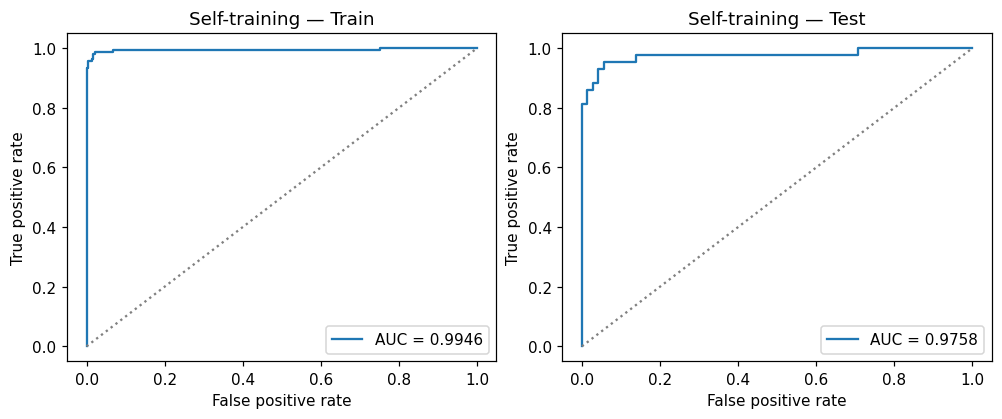

In [5]:
display(means.loc[means.method=="Self-training"].round(6))
trace=pd.read_csv(OUT/"self_training_trace.csv")
assert trace.groupby("run").size().eq(228).all()
print("Pseudo-label additions per run:",228)
run_one("Self-training")

### 1(b)(iii)(A). K-means initialization
I used k = 2 and 30 random initializations per training split, retaining the smallest within-cluster squared distance. Multiple starts reduce the chance of a poor local minimum; they do not prove that the global minimum was reached.

### 1(b)(iii)(B). Training labels and scores
For each centroid I found the closest 30 observations in the full training set and read only those labels for majority voting. More than 15 malignant labels gives a malignant cluster; a tie gives benign. Every training observation receives its assigned cluster's majority class.

### 1(b)(iii)(C). Test classification
I assigned each test observation to its nearest learned centroid and used that centroid's majority class. For ROC/AUC, I applied softmax to the negative Euclidean distances and summed the weights of centroids labeled malignant. These are ranking scores, not calibrated probabilities. Test labels never determine the cluster names.

K-means Train
K-means Test


,method,split,accuracy,precision,recall,F1,AUC
4,K-means,Train,0.927166,0.953188,0.846154,0.896317,0.980736
5,K-means,Test,0.922319,0.942333,0.845736,0.890053,0.977379


,Pred benign,Pred malignant
Actual benign,278,7
Actual malignant,25,144


,Pred benign,Pred malignant
Actual benign,70,2
Actual malignant,9,34


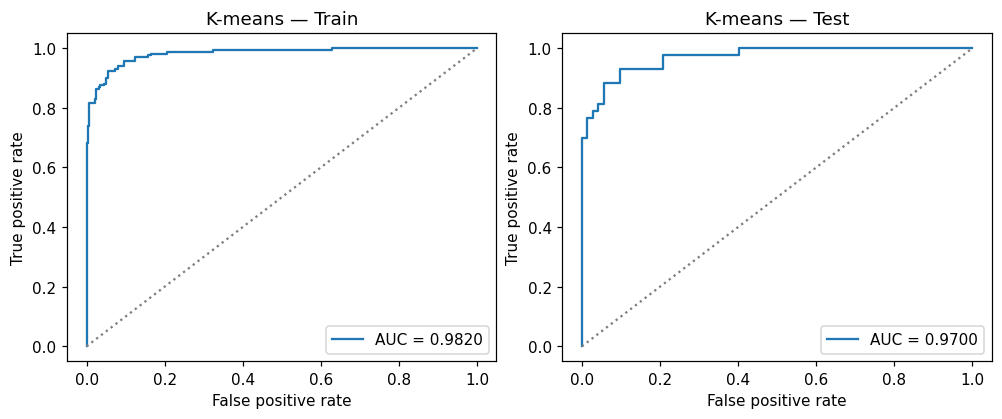

In [6]:
display(means.loc[means.method=="K-means"].round(6))
run_one("K-means")

### 1(b)(iv). Spectral clustering
Spectral clustering constructs an affinity graph, forms a graph-Laplacian embedding, and clusters the embedded coordinates. I used RBF affinities $\exp(-\|x_i-x_j\|^2)$, gamma = 1, two clusters, and 30 k-means starts in the embedding. Unlike centroid clustering, graph connectivity can represent non-convex groups.

I called fit_predict separately on the normalized training batch and test batch. Because spectral cluster indices are arbitrary and there is no built-in out-of-sample predict method, I matched the two test clusters to the two training clusters by maximizing their total mean pairwise RBF affinity. This matching uses only features; it does not use centroids or test labels.

Each training cluster's malignant fraction supplies its ROC score and, with a threshold of 0.5, its majority class. A test cluster inherits its matched training cluster's fraction and class. Thus the test procedure is batch/transductive: predictions depend on the unlabeled test batch. Its scores take at most two values, so its ROC curve is coarse. All labels used for naming clusters come from the training set, as permitted by the footnote.

Spectral Train
Spectral Test


,method,split,accuracy,precision,recall,F1,AUC
6,Spectral,Train,0.857856,0.984647,0.628008,0.766217,0.811080
7,Spectral,Test,0.841449,0.967223,0.596124,0.713706,0.792043


,Pred benign,Pred malignant
Actual benign,283,2
Actual malignant,64,105


,Pred benign,Pred malignant
Actual benign,71,1
Actual malignant,12,31


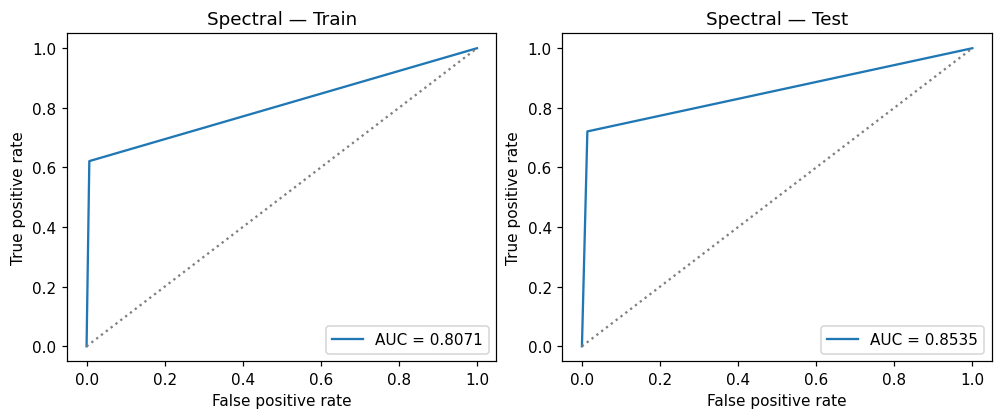

In [7]:
display(means.loc[means.method=="Spectral"].round(6))
run_one("Spectral")

### 1(b)(v). Comparison
The methods use different amounts of label information. Supervised learning uses every training label, and self-training begins with 226 labels. K-means uses labels near its centroids after fitting. Spectral clustering uses training labels only to name the clusters after fitting and uses the unlabeled test batch for its separate clustering.

,accuracy,precision,recall,F1,AUC
method,,,,,
Supervised,0.961449,0.957377,0.940310,0.948121,0.991225
Self-training,0.960580,0.967204,0.927132,0.946142,0.989104
K-means,0.922319,0.942333,0.845736,0.890053,0.977379
Spectral,0.841449,0.967223,0.596124,0.713706,0.792043


Supervised gives the highest mean test accuracy (96.14%). Self-training reaches 96.06%, compared with 96.14% for full supervision. K-means and spectral clustering reach 92.23% and 84.14%, respectively.

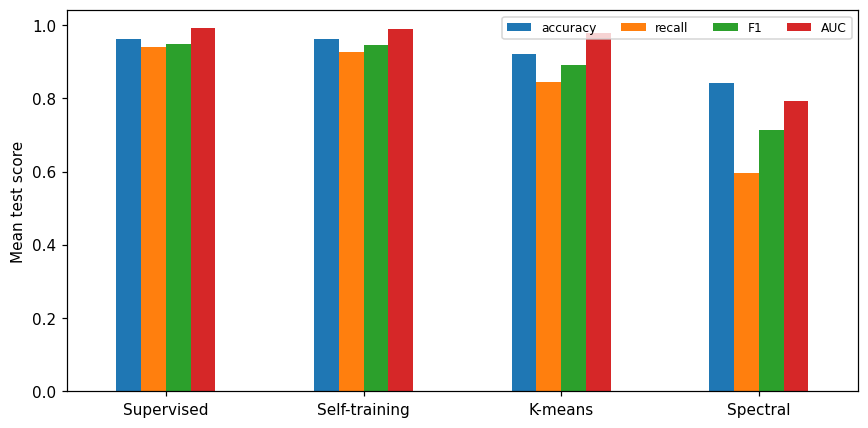

In [8]:
test_means=means.loc[means.split=="Test"].set_index("method")
display(test_means[metrics].round(6))
best=test_means.accuracy.idxmax()
answer(f'{best} gives the highest mean test accuracy ({test_means.loc[best,"accuracy"]:.2%}). '
       f'Self-training reaches {test_means.loc["Self-training","accuracy"]:.2%}, compared with '
       f'{test_means.loc["Supervised","accuracy"]:.2%} for full supervision. '
       f'K-means and spectral clustering reach {test_means.loc["K-means","accuracy"]:.2%} and '
       f'{test_means.loc["Spectral","accuracy"]:.2%}, respectively.')
fig,ax=plt.subplots(figsize=(8,4))
test_means[["accuracy","recall","F1","AUC"]].plot.bar(ax=ax)
ax.set(ylim=(0,1.04),ylabel="Mean test score",xlabel="");ax.tick_params(axis="x",rotation=0)
ax.legend(ncol=4,fontsize=8);fig.tight_layout();figure("breast_comparison")

The accuracy ordering agrees with the expected advantage of full supervision. Self-training is close, but its added labels are model predictions and can propagate earlier mistakes. K-means separates the classes fairly well, although it misses more malignant cases. With gamma fixed at 1, spectral clustering has the lowest malignant recall; its graph-based groups do not align as closely with the diagnosis labels.

## 2(a). Banknote authentication
I used the four numerical predictors and the binary class column. A fixed random split with seed 552 gives 900 training observations and 472 test observations. This split stays fixed throughout the 50 repetitions; the acquisition order changes between repetitions.

In [9]:
banknote=pd.read_csv(DATA/"data_banknote_authentication.txt",header=None)
assert banknote.shape==(1372,5) and not banknote.isna().any().any()
print("Observations:",len(banknote),"Predictors:",4)
if RECOMPUTE or not (OUT/"bank_learning_errors.csv").exists():
    bank=run_bank(DATA,OUT)
else:
    bank=pd.read_csv(OUT/"bank_learning_errors.csv")
assert len(bank)==50*90*2
print("Final fitted SVMs:",len(bank),"(plus cross-validation fits)")
split=pd.read_csv(OUT/"bank_split.csv");display(split.split.value_counts().to_frame("Count"))

Observations: 1372 Predictors: 4
Final fitted SVMs: 9000 (plus cross-validation fits)


,Count
split,
Train,900
Test,472


## 2(b)(i). Passive learning
For each repetition, I selected a random initial pool of ten training rows. I resampled if either class had fewer than two rows, so every five-fold fitting partition could retain both classes. Passive and active learning share this initial pool within each repetition.

I then added ten randomly selected remaining rows at a time, without replacement. At every pool size from 10 to 900, five-fold CV selected C from {0.01, 0.1, 1, 10}; a scaler fitted only on the fitting fold standardized the features. I refitted the selected model on the current pool and recorded its error on the fixed 472 test rows.

When both classes have at least five examples, CV is stratified. For a smaller minority count, I use shuffled five-fold partitions with both classes present in every fitting fold; a validation fold may contain one class. This retains five-fold CV without requiring a balanced initial sample.

In [10]:
passive=bank.loc[bank.method=="Passive"]
assert passive.groupby("run").size().eq(90).all()
display(passive.loc[passive.run==1].iloc[[0,1,4,9,19,49,89]].round(6))

,run,method,size,C,test_error
0,1,Passive,10,0.1,0.180085
1,1,Passive,20,1.0,0.025424
4,1,Passive,50,1.0,0.012712
9,1,Passive,100,10.0,0.014831
19,1,Passive,200,10.0,0.014831
49,1,Passive,500,1.0,0.008475
89,1,Passive,900,10.0,0.010593


## 2(b)(ii). Active learning
At each pool size, I fitted the same L1 linear SVM with five-fold selection of C. I ranked the remaining rows by the absolute decision value in that model's standardized feature space and selected the ten smallest values. Dividing by the weight-vector norm would preserve this ordering. I then queried their true labels and added them to the pool.

No row is acquired twice. The remaining rows' labels do not enter the acquisition ranking, and test labels do not enter either acquisition or model selection.

In [11]:
active=bank.loc[bank.method=="Active"]
assert active.groupby("run").size().eq(90).all()
display(active.loc[active.run==1].iloc[[0,1,4,9,19,49,89]].round(6))
orders=pd.read_csv(OUT/"bank_acquisition_order.csv")
assert orders.groupby(["run","method"]).train_position.nunique().eq(900).all()
print("Verified 900 unique acquired rows for every strategy and repetition.")

Verified 900 unique acquired rows for every strategy and repetition.


,run,method,size,C,test_error
90,1,Active,10,0.1,0.180085
91,1,Active,20,1.0,0.040254
94,1,Active,50,10.0,0.014831
99,1,Active,100,10.0,0.010593
109,1,Active,200,10.0,0.010593
139,1,Active,500,10.0,0.010593
179,1,Active,900,10.0,0.010593


## 2(c). Averaged learning curves
I averaged the 50 errors separately at each pool size. The shaded bands show ±1 sample standard deviation across acquisition runs, not confidence intervals. The same split and paired initial pools isolate the effect of acquisition order.

,method,size,mean_test_error,sd_test_error
0,Active,10,0.167924,0.106870
1,Active,20,0.049576,0.042653
2,Active,30,0.035212,0.039278
3,Active,40,0.021822,0.019139
4,Active,50,0.013729,0.009448
...,...,...,...,...
175,Passive,860,0.010636,0.001890
176,Passive,870,0.010381,0.001498
177,Passive,880,0.010424,0.001198
178,Passive,890,0.010424,0.001198


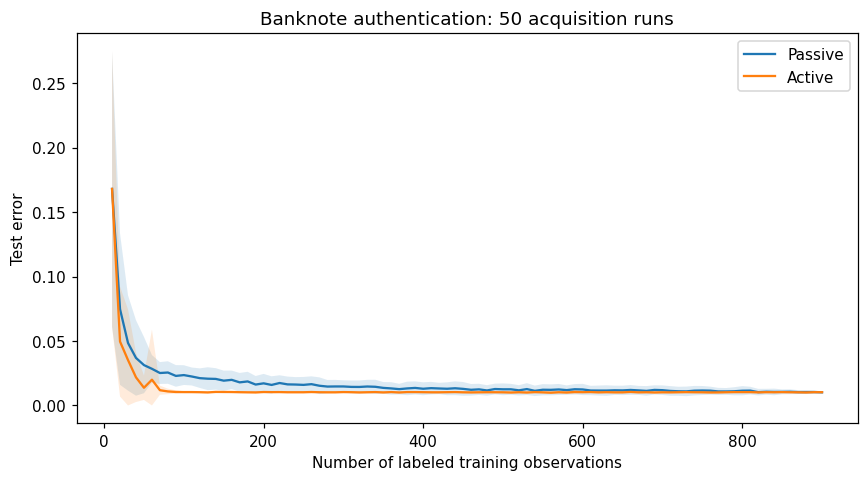

,method,size,mean_test_error,sd_test_error
0,Active,10,0.167924,0.106870
4,Active,50,0.013729,0.009448
9,Active,100,0.010381,0.000642
19,Active,200,0.010424,0.000581
39,Active,400,0.010297,0.000743
89,Active,900,0.010297,0.000743
90,Passive,10,0.167924,0.106870
94,Passive,50,0.031314,0.021831
99,Passive,100,0.023559,0.007653
109,Passive,200,0.017161,0.007330


Across the 90 pool sizes, mean test error is 1.302% for active learning and 1.732% for passive learning. This comparison averages the full learning curves; performance at individual pool sizes is shown above.

With 100 labels, active learning has mean test error 1.038%, compared with 2.356% for passive learning. Querying points near the current boundary makes the labels more useful early in learning. The curves approach each other as both pools cover nearly the entire training set; individual acquisition steps need not improve the error monotonically.

At 900 labeled rows, active and passive errors are 1.030% and 1.021%. Both now use the entire training set.

In [12]:
curve=bank.groupby(["method","size"],as_index=False).agg(mean_test_error=("test_error","mean"),
                                                           sd_test_error=("test_error","std"))
table(curve,"bank_learning_curve")
fig,ax=plt.subplots(figsize=(8,4.5))
for method in ["Passive","Active"]:
    d=curve[curve.method==method]
    ax.plot(d["size"],d.mean_test_error,label=method)
    ax.fill_between(d["size"],np.maximum(0,d.mean_test_error-d.sd_test_error),
                    d.mean_test_error+d.sd_test_error,alpha=.15)
ax.set(xlabel="Number of labeled training observations",ylabel="Test error",
       title="Banknote authentication: 50 acquisition runs")
ax.legend();fig.tight_layout();figure("bank_learning_curve")
chosen=curve[curve["size"].isin([10,50,100,200,400,900])]
table(chosen,"bank_selected_pool_sizes")
avg=bank.groupby("method").test_error.mean()
answer(f'Across the 90 pool sizes, mean test error is {avg["Active"]:.3%} for active learning '
       f'and {avg["Passive"]:.3%} for passive learning. '
       'This comparison averages the full learning curves; performance at individual pool sizes is shown above.')
at100=curve[curve["size"]==100].set_index("method")
answer(f'With 100 labels, active learning has mean test error {at100.loc["Active","mean_test_error"]:.3%}, '
       f'compared with {at100.loc["Passive","mean_test_error"]:.3%} for passive learning. '
       'Querying points near the current boundary makes the labels more useful early in learning. '
       'The curves approach each other as both pools cover nearly the entire training set; '
       'individual acquisition steps need not improve the error monotonically.')
end=curve[curve["size"]==900].set_index("method")
answer(f'At 900 labeled rows, active and passive errors are {end.loc["Active","mean_test_error"]:.3%} '
       f'and {end.loc["Passive","mean_test_error"]:.3%}. Both now use the entire training set.')

## References
- [Breast Cancer Wisconsin (Diagnostic), UCI](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).
- [Banknote Authentication, UCI](https://archive.ics.uci.edu/dataset/267/banknote+authentication).
- [scikit-learn: LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).
- [scikit-learn: SpectralClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html).
- [scikit-learn: KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- [SciPy: L-BFGS-B](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html).